# Sensitivity of Grover Search to an Incorrect Solution Count

## Research question

**How sensitive is standard Grover search to using an incorrect estimate $\hat{s}$ of the true number of marked states $s$?**

The previous validation established that the ideal statevector implementation reproduces the theoretical Grover trajectory to numerical precision.

The next question is therefore not whether the implementation follows standard Grover dynamics, but how those dynamics change when the stopping rule is computed from incorrect information about the number of solutions.

The central distinction in this notebook is:

$$
s
=
\text{true number of marked states}
$$

and

$$
\hat{s}
=
\text{assumed number of marked states}.
$$

The oracle always marks exactly $s$ states.

Only the stopping rule uses $\hat{s}$.

## 1. Mathematical setup

For a search space of size

$$
N=2^n,
$$

with $s$ true marked states, define

$$
\theta
=
\arcsin\sqrt{\frac{s}{N}}.
$$

If $s$ were known exactly, the continuous first maximum would occur near

$$
t_{\mathrm{continuous}}
=
\frac{\pi}{4\theta}
-
\frac{1}{2}.
$$

However, suppose the algorithm assumes that the marked count is $\hat{s}$.

It then constructs an assumed angle

$$
\hat{\theta}
=
\arcsin\sqrt{\frac{\hat{s}}{N}},
$$

and chooses a stopping time using $\hat{\theta}$, not the true $\theta$.

Let that integer stopping time be

$$
t(\hat{s}).
$$

The actual success probability is still governed by the true marked count $s$:

$$
\boxed{
P(s,\hat{s})
=
\sin^2
\left(
(2t(\hat{s})+1)\theta
\right)
}
$$

with

$$
\theta
=
\arcsin\sqrt{\frac{s}{N}}.
$$

This equation isolates the entire sensitivity problem.

The assumed value $\hat{s}$ determines when the algorithm stops.

The true value $s$ determines how far the quantum state has actually rotated.

### 1.3 Domain of the true marked count

The sensitivity study uses the nontrivial Grover regime

$$
1\le s<N.
$$

The edge case $s=N$ has success probability $1$ before any Grover iteration and the usual marked and unmarked two dimensional decomposition degenerates because there is no unmarked subspace.

The assumed count may still satisfy

$$
1\le\hat{s}\le N,
$$

because $\hat{s}=N$ simply induces the stopping decision $t=0$.


### 1.1 What should underestimation do?

If

$$
\hat{s}<s,
$$

the algorithm assumes that marked states are rarer than they really are.

Since

$$
\hat{s}\downarrow
\Rightarrow
\hat{\theta}\downarrow,
$$

the estimated useful iteration count tends to increase.

So underestimation should generally encourage the algorithm to run for too many Grover iterations.

The expected mechanism is therefore overshooting.

This is a hypothesis to test, not a conclusion to assume.

### 1.2 What should overestimation do?

If

$$
\hat{s}>s,
$$

the algorithm assumes that marked states are more common than they really are.

Then

$$
\hat{s}\uparrow
\Rightarrow
\hat{\theta}\uparrow,
$$

so the estimated useful iteration count tends to decrease.

The likely mechanism is under amplification: the algorithm stops before the state has rotated sufficiently toward the marked subspace.

Again, the experiment will determine how strongly this effect appears.

## 2. Implementation setup

The implementation follows the same ideal Grover model used for the baseline validation.

The oracle always contains exactly the true number of marked states $s$.

The assumed value $\hat{s}$ affects only the stopping rule.

This separation is essential. If the oracle itself were changed to contain $\hat{s}$ marked states, the experiment would no longer represent uncertainty about the solution count.

### 2.1 Imports

In [1]:
from math import asin, sqrt, sin, pi, floor, ceil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

try:
    from qiskit.circuit.library import DiagonalGate
except ImportError:
    from qiskit.circuit.library import Diagonal as DiagonalGate

print("Qiskit version:", qiskit.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

Qiskit version: 2.3.0
NumPy version: 2.4.2
Pandas version: 3.0.0


### 2.2 Marked state construction

For reproducibility, the first $s$ computational basis states are marked.

The exact labels are not the variable under study here. The experiment varies only the relationship between the true marked count $s$ and the assumed count $\hat{s}$.

In [2]:
def make_marked_states(n: int, s: int):
    """Return exactly s distinct n bit computational basis states."""
    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError("n must be a positive integer")

    N = 2 ** int(n)

    if not isinstance(s, (int, np.integer)):
        raise ValueError("s must be an integer")

    if not 1 <= int(s) < N:
        raise ValueError("s must satisfy 1 <= s < 2**n")

    marked = [
        format(i, f"0{int(n)}b")
        for i in range(int(s))
    ]

    assert len(marked) == int(s)
    assert len(set(marked)) == int(s)

    return marked

### 2.3 Grover circuit

The phase oracle applies

$$
|x\rangle
\mapsto
(-1)^{f(x)}|x\rangle,
$$

where $f(x)=1$ for marked states.

The diffusion step implements the reflection about the uniform state.

Together they produce the usual Grover rotation.

In [3]:
def validate_iteration_count(t):
    if not isinstance(t, (int, np.integer)) or t < 0:
        raise ValueError("t must be a nonnegative integer")

    return int(t)


def build_phase_oracle(n: int, marked):
    N = 2 ** n
    phases = np.ones(N, dtype=complex)

    for bitstring in marked:
        phases[int(bitstring, 2)] = -1.0

    return DiagonalGate(phases.tolist())


def apply_zero_state_phase_flip(circuit: QuantumCircuit, qubits):
    qubits = list(qubits)

    if len(qubits) == 1:
        q = qubits[0]
        circuit.x(q)
        circuit.z(q)
        circuit.x(q)
        return

    for q in qubits:
        circuit.x(q)

    controls = qubits[:-1]
    target = qubits[-1]

    circuit.h(target)
    circuit.mcx(controls, target)
    circuit.h(target)

    for q in qubits:
        circuit.x(q)


def apply_diffusion(circuit: QuantumCircuit, qubits):
    qubits = list(qubits)

    for q in qubits:
        circuit.h(q)

    apply_zero_state_phase_flip(circuit, qubits)

    for q in qubits:
        circuit.h(q)


def build_grover_circuit(n: int, marked, t: int):
    t = validate_iteration_count(t)

    qc = QuantumCircuit(n)
    qc.h(range(n))

    oracle = build_phase_oracle(n, marked)

    for _ in range(t):
        qc.append(oracle, range(n))
        apply_diffusion(qc, range(n))

    return qc


def simulation_success_probability(n: int, marked, t: int) -> float:
    t = validate_iteration_count(t)

    qc = build_grover_circuit(n, marked, t)
    state = Statevector.from_instruction(qc)
    probabilities = state.probabilities()

    return float(
        sum(
            probabilities[int(bitstring, 2)]
            for bitstring in marked
        )
    )

### 2.4 Stopping rule based on the assumed count

For an assumed marked count $\hat{s}$,

$$
\hat{\theta}
=
\arcsin\sqrt{\frac{\hat{s}}{N}}.
$$

The continuous optimum is

$$
\hat{t}_{\mathrm{continuous}}
=
\frac{\pi}{4\hat{\theta}}
-
\frac{1}{2}.
$$

Since Grover iterations are discrete, the two neighboring integers are compared and the one with larger success probability under the assumed model is selected.

This ensures that any loss in performance comes from using the wrong marked count, not from an avoidable rounding convention.

In [4]:
def grover_theory_probability(N: int, s: int, t: int) -> float:
    if not isinstance(N, (int, np.integer)) or N < 2:
        raise ValueError("N must be an integer at least 2")

    if not isinstance(s, (int, np.integer)):
        raise ValueError("s must be an integer")

    if not 1 <= int(s) < int(N):
        raise ValueError("s must satisfy 1 <= s < N")

    t = validate_iteration_count(t)

    theta = asin(sqrt(int(s) / int(N)))
    return sin((2 * t + 1) * theta) ** 2


def stopping_time_from_assumed_s(N: int, s_hat: int) -> int:
    if not isinstance(N, (int, np.integer)) or N < 2:
        raise ValueError("N must be an integer at least 2")

    if not isinstance(s_hat, (int, np.integer)):
        raise ValueError("s_hat must be an integer")

    if not 1 <= int(s_hat) <= int(N):
        raise ValueError("s_hat must satisfy 1 <= s_hat <= N")

    # If every state is assumed marked, the best action is to
    # measure the uniform state immediately.
    if int(s_hat) == int(N):
        return 0

    theta_hat = asin(sqrt(int(s_hat) / int(N)))
    t_continuous = pi / (4 * theta_hat) - 0.5

    candidates = {
        max(0, floor(t_continuous)),
        max(0, ceil(t_continuous)),
    }

    return max(
        candidates,
        key=lambda t:
            grover_theory_probability(
                int(N),
                int(s_hat),
                int(t),
            ),
    )


def success_probability_with_wrong_s(
    N: int,
    s_true: int,
    s_hat: int,
) -> float:
    t = stopping_time_from_assumed_s(N, s_hat)
    return grover_theory_probability(
        N,
        s_true,
        t,
    )

## 3. Single controlled case

Begin with

$$
N=256,
\qquad
s=4.
$$

The true oracle therefore contains exactly four marked states.

Now deliberately choose the stopping time using

$$
\hat{s}
\in
\{1,2,4,8,16,32\}.
$$

For every assumed value we record:

$$
\hat{s},
\qquad
\frac{\hat{s}}{s},
\qquad
t(\hat{s}),
\qquad
P_{\mathrm{theory}},
\qquad
P_{\mathrm{sim}}.
$$

The case $\hat{s}=s$ provides the reference point.

In [5]:
n_single = 8
N_single = 2 ** n_single
s_true_single = 4
s_hat_values = [1, 2, 4, 8, 16, 32]

marked_single = make_marked_states(n_single, s_true_single)

single_rows = []

for s_hat in s_hat_values:
    t_used = stopping_time_from_assumed_s(N_single, s_hat)

    p_theory = grover_theory_probability(
        N_single,
        s_true_single,
        t_used,
    )

    p_sim = simulation_success_probability(
        n_single,
        marked_single,
        t_used,
    )

    single_rows.append({
        "N": N_single,
        "s_true": s_true_single,
        "s_hat": s_hat,
        "ratio_s_hat_over_s": s_hat / s_true_single,
        "t_used": t_used,
        "P_theory": p_theory,
        "P_sim": p_sim,
        "absolute_error": abs(p_sim - p_theory),
    })

single_case_df = pd.DataFrame(single_rows)
single_case_df

,N,s_true,s_hat,ratio_s_hat_over_s,t_used,P_theory,P_sim,absolute_error
0,256,4,1,0.25,12,0.000071,0.000071,7.237050e-18
1,256,4,2,0.50,8,0.718042,0.718042,1.338929e-13
2,256,4,4,1.00,6,0.996586,0.996586,1.391109e-13
3,256,4,8,2.00,4,0.816377,0.816377,7.727152e-14
4,256,4,16,4.00,3,0.591380,0.591380,4.207745e-14
5,256,4,32,8.00,2,0.343895,0.343895,1.582068e-14


### 3.1 Visualizing the controlled case

The first plot asks a simple question:

> How does success probability change as the assumed number of solutions moves away from the truth?

The second quantity to watch is the chosen stopping time $t(\hat{s})$.

If underestimation causes overshooting, then smaller $\hat{s}$ should correspond to larger stopping times.

If overestimation causes under amplification, larger $\hat{s}$ should correspond to smaller stopping times.

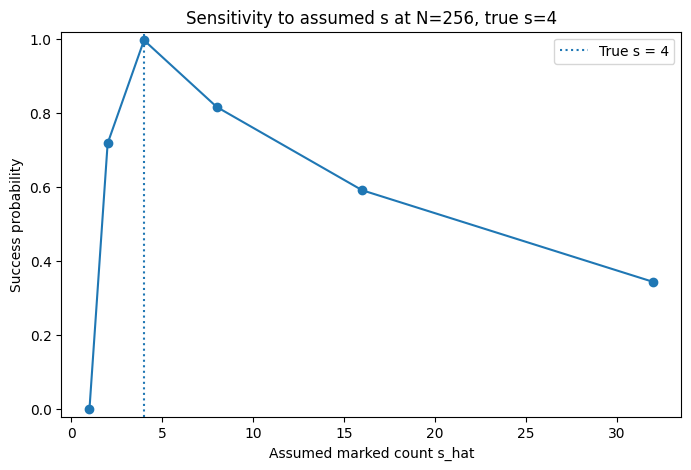

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(
    single_case_df["s_hat"],
    single_case_df["P_sim"],
    marker="o",
)

plt.axvline(
    s_true_single,
    linestyle=":",
    label=f"True s = {s_true_single}",
)

plt.xlabel("Assumed marked count s_hat")
plt.ylabel("Success probability")
plt.title(f"Sensitivity to assumed s at N={N_single}, true s={s_true_single}")
plt.ylim(-0.02, 1.02)
plt.legend()
plt.show()

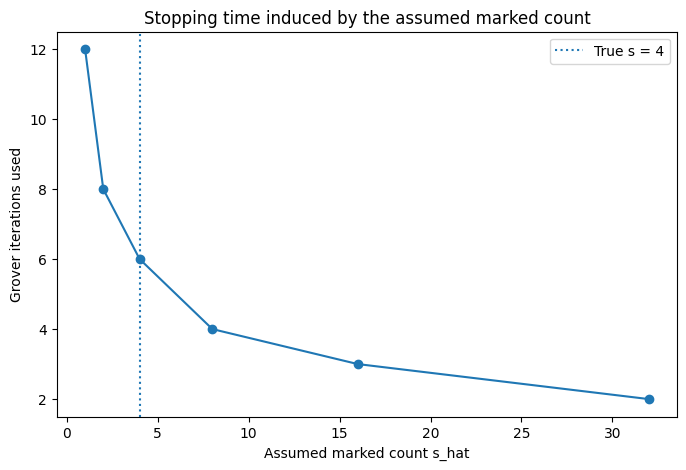

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    single_case_df["s_hat"],
    single_case_df["t_used"],
    marker="o",
)

plt.axvline(
    s_true_single,
    linestyle=":",
    label=f"True s = {s_true_single}",
)

plt.xlabel("Assumed marked count s_hat")
plt.ylabel("Grover iterations used")
plt.title("Stopping time induced by the assumed marked count")
plt.legend()
plt.show()

## 4. Full sensitivity matrix

A single true value of $s$ cannot show whether the observed behavior generalizes.

Fix

$$
N=256
$$

and compare

$$
s
\in
\{1,2,4,8,16,32\}
$$

against

$$
\hat{s}
\in
\{1,2,4,8,16,32\}.
$$

Each matrix entry contains

$$
P(s,\hat{s}).
$$

The diagonal

$$
s=\hat{s}
$$

represents exact knowledge.

Off diagonal entries represent different kinds and magnitudes of misspecification.

In [8]:
n_matrix = 8
N_matrix = 2 ** n_matrix

s_true_values = [1, 2, 4, 8, 16, 32]
s_hat_values = [1, 2, 4, 8, 16, 32]

matrix_rows = []

for s_true in s_true_values:
    marked = make_marked_states(n_matrix, s_true)

    for s_hat in s_hat_values:
        t_used = stopping_time_from_assumed_s(N_matrix, s_hat)

        p_theory = grover_theory_probability(
            N_matrix,
            s_true,
            t_used,
        )

        p_sim = simulation_success_probability(
            n_matrix,
            marked,
            t_used,
        )

        matrix_rows.append({
            "N": N_matrix,
            "s_true": s_true,
            "s_hat": s_hat,
            "ratio_s_hat_over_s": s_hat / s_true,
            "absolute_count_error": abs(s_hat - s_true),
            "t_used": t_used,
            "P_theory": p_theory,
            "P_sim": p_sim,
            "absolute_error": abs(p_sim - p_theory),
        })

sensitivity_df = pd.DataFrame(matrix_rows)
sensitivity_df.head()

,N,s_true,s_hat,ratio_s_hat_over_s,absolute_count_error,t_used,P_theory,P_sim,absolute_error
0,256,1,1,1.0,0,12,0.999947,0.999947,5.415668e-13
1,256,1,2,2.0,1,8,0.763722,0.763722,2.757794e-13
2,256,1,4,4.0,3,6,0.527618,0.527618,1.381117e-13
3,256,1,8,8.0,7,4,0.284743,0.284743,4.762857e-14
4,256,1,16,16.0,15,3,0.179721,0.179721,2.250977e-14


### 4.1 Success probability table

The matrix form makes the asymmetry between underestimation and overestimation easier to inspect.

Rows are true marked counts $s$.

Columns are assumed marked counts $\hat{s}$.

In [9]:
success_matrix = sensitivity_df.pivot(
    index="s_true",
    columns="s_hat",
    values="P_sim",
)

success_matrix

s_hat,1,2,4,8,16,32
s_true,,,,,,
1,0.999947,0.763722,0.527618,0.284743,0.179721,0.094638
2,0.641632,0.995620,0.833548,0.511136,0.337154,0.183370
4,0.000071,0.718042,0.996586,0.816377,0.591380,0.343895
8,0.929048,0.014453,0.545892,0.999182,0.896937,0.602425
16,0.001143,0.836089,0.020381,0.581704,0.961319,0.908447
32,0.144965,0.019457,0.999786,0.012207,0.330078,0.945312


### 4.2 Heatmap

The heatmap provides a visual map of the region in which standard Grover search remains effective despite an incorrect estimate.

The diagonal is not expected to be exactly one in every case because the optimal continuous stopping point may fall between integer iteration counts.

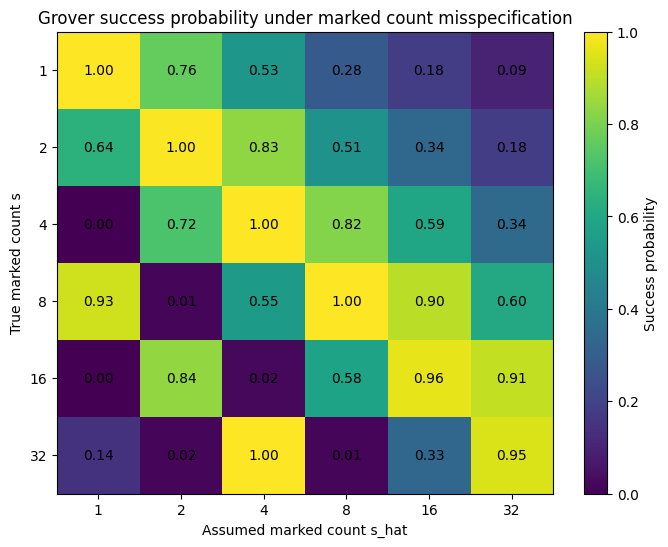

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))

image = ax.imshow(
    success_matrix.values,
    aspect="auto",
    vmin=0,
    vmax=1,
)

ax.set_xticks(range(len(success_matrix.columns)))
ax.set_xticklabels(success_matrix.columns)

ax.set_yticks(range(len(success_matrix.index)))
ax.set_yticklabels(success_matrix.index)

ax.set_xlabel("Assumed marked count s_hat")
ax.set_ylabel("True marked count s")
ax.set_title("Grover success probability under marked count misspecification")

for i in range(success_matrix.shape[0]):
    for j in range(success_matrix.shape[1]):
        ax.text(
            j,
            i,
            f"{success_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
        )

fig.colorbar(image, ax=ax, label="Success probability")
plt.show()

## 5. Underestimation versus overestimation

Classify each experiment by the relationship between $\hat{s}$ and $s$:

$$
\hat{s}<s
\quad\Rightarrow\quad
\text{underestimate}
$$

$$
\hat{s}=s
\quad\Rightarrow\quad
\text{exact}
$$

$$
\hat{s}>s
\quad\Rightarrow\quad
\text{overestimate}.
$$

The purpose is not merely to calculate three averages.

We want to determine whether the two directions of error produce systematically different behavior and whether that difference can be explained by the Grover rotation picture.

In [11]:
def classify_estimate(row):
    if row["s_hat"] < row["s_true"]:
        return "underestimate"
    if row["s_hat"] > row["s_true"]:
        return "overestimate"
    return "exact"

sensitivity_df["estimate_type"] = sensitivity_df.apply(
    classify_estimate,
    axis=1,
)

estimate_type_summary = (
    sensitivity_df
    .groupby("estimate_type")["P_sim"]
    .agg(["count", "mean", "median", "min", "max"])
)

estimate_type_summary

,count,mean,median,min,max
estimate_type,,,,,
exact,6,0.982994,0.996103,0.945312,0.999947
overestimate,15,0.525007,0.527618,0.094638,0.908447
underestimate,15,0.386330,0.330078,0.000071,0.999786


### 5.1 Matched multiplicative asymmetry

The aggregate underestimate and overestimate means mix several error magnitudes.

To test directional asymmetry more directly, compare reciprocal multiplicative errors of the same size:

$$
\frac{\hat{s}}{s}
=
\frac1k
\qquad\text{versus}\qquad
\frac{\hat{s}}{s}
=
k.
$$

For each factor $k$, average only the cases in which the corresponding ratio is actually present in the sensitivity matrix.

This separates the direction of the error from its multiplicative magnitude.

In [12]:
matched_factor_rows = []

available_ratios = set(
    sensitivity_df[
        "ratio_s_hat_over_s"
    ].astype(float)
)

for factor in [2, 4, 8, 16, 32]:
    under_ratio = 1 / factor
    over_ratio = factor

    if (
        under_ratio not in available_ratios
        or over_ratio not in available_ratios
    ):
        continue

    under_values = sensitivity_df.loc[
        np.isclose(
            sensitivity_df["ratio_s_hat_over_s"],
            under_ratio,
        ),
        "P_sim",
    ]

    over_values = sensitivity_df.loc[
        np.isclose(
            sensitivity_df["ratio_s_hat_over_s"],
            over_ratio,
        ),
        "P_sim",
    ]

    matched_factor_rows.append({
        "factor": factor,
        "under_ratio": under_ratio,
        "under_count": int(len(under_values)),
        "under_mean": float(under_values.mean()),
        "over_ratio": over_ratio,
        "over_count": int(len(over_values)),
        "over_mean": float(over_values.mean()),
        "under_minus_over":
            float(
                under_values.mean()
                - over_values.mean()
            ),
    })

matched_asymmetry_df = pd.DataFrame(
    matched_factor_rows
)

matched_asymmetry_df

,factor,under_ratio,under_count,under_mean,over_ratio,over_count,over_mean,under_minus_over
0,2,0.50000,5,0.563470,2,5,0.843806,-0.280336
1,4,0.25000,4,0.011778,4,4,0.558139,-0.546362
2,8,0.12500,3,0.921641,8,3,0.321931,0.599710
3,16,0.06250,2,0.010300,16,2,0.181545,-0.171245
4,32,0.03125,1,0.144965,32,1,0.094638,0.050328


## 6. Is multiplicative error more informative than absolute error?

An absolute count error of one means very different things in different regimes.

For example,

$$
1\rightarrow2
$$

doubles the assumed number of marked states, while

$$
31\rightarrow32
$$

changes it only slightly.

This suggests that the ratio

$$
r
=
\frac{\hat{s}}{s}
$$

may be more informative than the absolute difference

$$
|\hat{s}-s|.
$$

If sensitivity approximately collapses when expressed in terms of $r$, then the problem is primarily multiplicative rather than additive.

In [13]:
ratio_summary = (
    sensitivity_df
    .groupby("ratio_s_hat_over_s")["P_sim"]
    .agg(["count", "mean", "median", "min", "max"])
    .reset_index()
    .sort_values("ratio_s_hat_over_s")
)

ratio_summary

,ratio_s_hat_over_s,count,mean,median,min,max
0,0.03125,1,0.144965,0.144965,0.144965,0.144965
1,0.06250,2,0.010300,0.010300,0.001143,0.019457
2,0.12500,3,0.921641,0.929048,0.836089,0.999786
3,0.25000,4,0.011778,0.013330,0.000071,0.020381
4,0.50000,5,0.563470,0.581704,0.330078,0.718042
5,1.00000,6,0.982994,0.996103,0.945312,0.999947
6,2.00000,5,0.843806,0.833548,0.763722,0.908447
7,4.00000,4,0.558139,0.559499,0.511136,0.602425
8,8.00000,3,0.321931,0.337154,0.284743,0.343895
9,16.00000,2,0.181545,0.181545,0.179721,0.183370


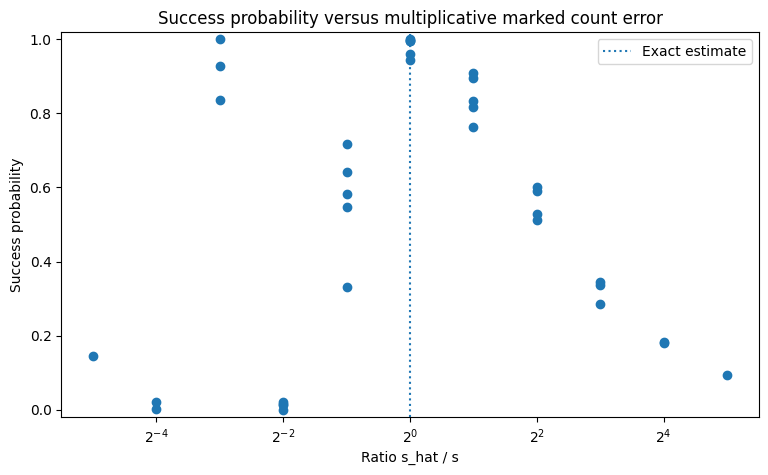

In [14]:
plt.figure(figsize=(9, 5))

plt.scatter(
    sensitivity_df["ratio_s_hat_over_s"],
    sensitivity_df["P_sim"],
)

plt.axvline(
    1.0,
    linestyle=":",
    label="Exact estimate",
)

plt.xscale("log", base=2)
plt.xlabel("Ratio s_hat / s")
plt.ylabel("Success probability")
plt.title("Success probability versus multiplicative marked count error")
plt.ylim(-0.02, 1.02)
plt.legend()
plt.show()

### 6.1 Why use a logarithmic horizontal axis?

Ratios below one and above one should be interpreted multiplicatively.

For example,

$$
\frac{\hat{s}}{s}
=
\frac{1}{2}
$$

and

$$
\frac{\hat{s}}{s}
=
2
$$

represent symmetric factor of two errors in opposite directions.

A base two logarithmic axis places such multiplicative deviations naturally around the exact value

$$
\frac{\hat{s}}{s}=1.
$$

## 7. Robustness thresholds

A useful practical question is:

> How wrong can $\hat{s}$ be before standard Grover search becomes unreliable?

There is no unique probability threshold that defines reliability, so several reference levels are examined:

$$
0.90,
\qquad
0.75,
\qquad
0.50.
$$

Because Grover success probability is oscillatory, the set of estimates that pass a threshold need not form one continuous interval around the true $s$.

For that reason, the analysis records the **actual passing estimates**

$$
\{\hat{s}:P(s,\hat{s})\ge \tau\}
$$

for each threshold $\tau$, rather than only reporting the minimum and maximum passing values.

This distinction is important because two distant estimates may pass while intermediate estimates fail.

In [15]:
thresholds = [0.90, 0.75, 0.50]

threshold_rows = []

for s_true in s_true_values:
    subset = sensitivity_df[
        sensitivity_df["s_true"] == s_true
    ].sort_values("s_hat")

    for threshold in thresholds:
        passing = subset[
            subset["P_sim"] >= threshold
        ].copy()

        passing_s_hat = passing["s_hat"].astype(int).tolist()
        passing_ratios = passing["ratio_s_hat_over_s"].tolist()

        threshold_rows.append({
            "s_true": s_true,
            "threshold": threshold,
            "passing_s_hat": passing_s_hat,
            "passing_ratios": passing_ratios,
            "count_passing": len(passing),
        })

robustness_df = pd.DataFrame(threshold_rows)
robustness_df

,s_true,threshold,passing_s_hat,passing_ratios,count_passing
0,1,0.90,[1],[1.0],1
1,1,0.75,"[1, 2]","[1.0, 2.0]",2
2,1,0.50,"[1, 2, 4]","[1.0, 2.0, 4.0]",3
3,2,0.90,[2],[1.0],1
4,2,0.75,"[2, 4]","[1.0, 2.0]",2
5,2,0.50,"[1, 2, 4, 8]","[0.5, 1.0, 2.0, 4.0]",4
6,4,0.90,[4],[1.0],1
7,4,0.75,"[4, 8]","[1.0, 2.0]",2
8,4,0.50,"[2, 4, 8, 16]","[0.5, 1.0, 2.0, 4.0]",4
9,8,0.90,"[1, 8]","[0.125, 1.0]",2


## 8. Extending beyond one search space size

The fixed $N=256$ matrix reveals the local sensitivity structure, but changing $N$ while keeping the same absolute values of $s$ also changes the marked fraction

$$
\frac{s}{N}.
$$

That would confound search space size with the underlying Grover angle.

To isolate the effect of $N$ more cleanly, the cross scale experiment instead holds

$$
\frac{N}{s}
$$

fixed across several search space sizes.

The tested scale ratios are

$$
\frac{N}{s}
\in
\{8,16,32,64\},
$$

for

$$
N
\in
\{64,128,256,512\}.
$$

For each matched marked fraction, the experiment applies the same requested multiplicative perturbations

$$
\frac14,
\quad
\frac12,
\quad
1,
\quad
2,
\quad
4
$$

to the assumed count.

Because $\hat{s}$ must be an integer, both the requested and realized ratios are recorded.

This design asks a sharper question:

> Once the marked fraction is held fixed, does changing the absolute search space size introduce an additional systematic change in sensitivity?

In [16]:
n_values = [6, 7, 8, 9]
N_over_s_values = [8, 16, 32, 64]
ratio_targets = [0.25, 0.5, 1.0, 2.0, 4.0]

cross_scale_rows = []

for n_case in n_values:
    N_case = 2 ** n_case

    for N_over_s in N_over_s_values:
        if N_case % N_over_s != 0:
            continue

        s_true = N_case // N_over_s

        if not 1 <= s_true < N_case:
            continue

        marked = make_marked_states(
            n_case,
            s_true,
        )

        seen_s_hat = set()

        for ratio_target in ratio_targets:
            s_hat = int(
                round(
                    s_true * ratio_target
                )
            )

            s_hat = max(
                1,
                min(N_case, s_hat),
            )

            if s_hat in seen_s_hat:
                continue

            seen_s_hat.add(s_hat)

            t_used = (
                stopping_time_from_assumed_s(
                    N_case,
                    s_hat,
                )
            )

            p_sim = (
                simulation_success_probability(
                    n_case,
                    marked,
                    t_used,
                )
            )

            cross_scale_rows.append({
                "n": n_case,
                "N": N_case,
                "s_true": s_true,
                "N_over_s": N_over_s,
                "requested_ratio":
                    ratio_target,
                "s_hat": s_hat,
                "realized_ratio":
                    s_hat / s_true,
                "t_used": t_used,
                "P_sim": p_sim,
            })

cross_scale_df = pd.DataFrame(
    cross_scale_rows
)

assert not cross_scale_df.duplicated(
    subset=[
        "N",
        "s_true",
        "s_hat",
    ]
).any()

cross_scale_df.head()

,n,N,s_true,N_over_s,requested_ratio,s_hat,realized_ratio,t_used,P_sim
0,6,64,8,8,0.25,2,0.25,4,0.012207
1,6,64,8,8,0.50,4,0.50,3,0.330078
2,6,64,8,8,1.00,8,1.00,2,0.945312
3,6,64,8,8,2.00,16,2.00,1,0.781250
4,6,64,8,8,4.00,32,4.00,0,0.125000


In [17]:
cross_scale_summary = (
    cross_scale_df
    .groupby(
        [
            "N_over_s",
            "N",
            "realized_ratio",
        ]
    )["P_sim"]
    .agg(
        ["count", "mean", "median", "min", "max"]
    )
    .reset_index()
    .sort_values(
        [
            "N_over_s",
            "realized_ratio",
            "N",
        ]
    )
)

cross_scale_summary

,N_over_s,N,realized_ratio,count,mean,median,min,max
0,8,64,0.25,1,0.012207,0.012207,0.012207,0.012207
5,8,128,0.25,1,0.012207,0.012207,0.012207,0.012207
10,8,256,0.25,1,0.012207,0.012207,0.012207,0.012207
15,8,512,0.25,1,0.012207,0.012207,0.012207,0.012207
1,8,64,0.50,1,0.330078,0.330078,0.330078,0.330078
...,...,...,...,...,...,...,...,...
74,64,512,2.00,1,0.816377,0.816377,0.816377,0.816377
61,64,64,4.00,1,0.591380,0.591380,0.591380,0.591380
65,64,128,4.00,1,0.591380,0.591380,0.591380,0.591380
70,64,256,4.00,1,0.591380,0.591380,0.591380,0.591380


In [18]:
matched_fraction_summary = (
    cross_scale_df
    .groupby(
        [
            "N_over_s",
            "realized_ratio",
        ]
    )["P_sim"]
    .agg(
        count="count",
        mean="mean",
        std="std",
        min="min",
        max="max",
    )
    .reset_index()
    .sort_values(
        [
            "N_over_s",
            "realized_ratio",
        ]
    )
)

matched_fraction_summary

,N_over_s,realized_ratio,count,mean,std,min,max
0,8,0.25,4,0.012207,9.442745e-16,0.012207,0.012207
1,8,0.50,4,0.330078,1.537779e-14,0.330078,0.330078
2,8,1.00,4,0.945312,3.058263e-14,0.945312,0.945312
3,8,2.00,4,0.781250,1.230062e-14,0.781250,0.781250
4,8,4.00,4,0.125000,4.388542e-17,0.125000,0.125000
5,16,0.25,4,0.020381,1.869935e-15,0.020381,0.020381
6,16,0.50,4,0.581704,3.712762e-14,0.581704,0.581704
7,16,1.00,4,0.961319,4.617411e-14,0.961319,0.961319
8,16,2.00,4,0.908447,2.897037e-14,0.908447,0.908447
9,16,4.00,4,0.472656,7.507015e-15,0.472656,0.472656


### 8.1 Matched marked fraction comparison

For each fixed value of $N/s$, compare success probability across the different search space sizes.

If the ideal Grover model depends only on the marked fraction and the realized assumed ratio, the curves should overlap up to integer stopping effects.

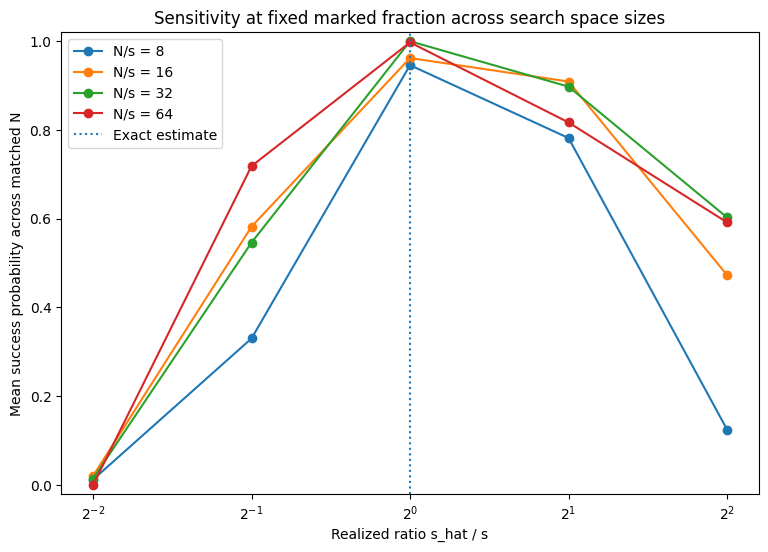

In [19]:
plt.figure(figsize=(9, 6))

for N_over_s in N_over_s_values:
    subset = matched_fraction_summary[
        matched_fraction_summary[
            "N_over_s"
        ] == N_over_s
    ]

    plt.plot(
        subset["realized_ratio"],
        subset["mean"],
        marker="o",
        label=f"N/s = {N_over_s}",
    )

plt.axvline(
    1.0,
    linestyle=":",
    label="Exact estimate",
)

plt.xscale("log", base=2)
plt.xlabel("Realized ratio s_hat / s")
plt.ylabel("Mean success probability across matched N")
plt.title("Sensitivity at fixed marked fraction across search space sizes")
plt.ylim(-0.02, 1.02)
plt.legend()
plt.show()

## 9. Analysis questions

After executing the notebook, the results should be interpreted through the following questions.

### 9.1 Does incorrect knowledge of $s$ always reduce success?

Not necessarily.

Because Grover dynamics are discrete and oscillatory, a nearby incorrect estimate can occasionally select an integer iteration count that performs almost as well as the exact estimate.

The important object is therefore the resulting stopping time and rotation angle, not merely whether

$$
\hat{s}=s.
$$

### 9.2 Is underestimation systematically worse than overestimation?

The geometric expectation is asymmetric.

Underestimation tends to increase the number of iterations and can push the state beyond the first useful maximum.

Overestimation tends to stop early.

The aggregate summary is supplemented by matched reciprocal error factors so that direction can be compared at the same multiplicative magnitude.

### 9.3 Does the ratio $\hat{s}/s$ organize the data?

If cases with similar realized multiplicative error show similar success probabilities across different $s$, then

$$
\frac{\hat{s}}{s}
$$

is a more natural sensitivity variable than absolute count error.

The cross scale experiment also holds the marked fraction fixed so that changes in $N$ are not confounded with changes in $s/N$.

### 9.4 How wide is the robust region?

The threshold analysis determines whether standard Grover search requires nearly exact knowledge of $s$, or whether a nontrivial range of estimation error still produces useful success probability.

### 9.5 What if the sensitivity is irregular?

Irregularity is not automatically an implementation failure.

Because

$$
P(t)
=
\sin^2((2t+1)\theta),
$$

small changes in the integer stopping time can move the state to very different points on an oscillatory trajectory.

Any irregular pattern should therefore be traced back to the actual $t(\hat{s})$ values before being interpreted.

## 10. Results and interpretation

### 10.1 Controlled case: $N=256,\ s=4$

The controlled case shows clearly how an incorrect estimate changes the stopping time and, through that stopping time, the final success probability.

With the correct estimate

$$
\hat{s}=4,
$$

the stopping rule selects

$$
t=6
$$

and the success probability is

$$
P\approx0.996586.
$$

A moderate underestimate,

$$
\hat{s}=2,
$$

uses

$$
t=8
$$

and still retains

$$
P\approx0.718042.
$$

A stronger underestimate,

$$
\hat{s}=1,
$$

uses

$$
t=12
$$

and the success probability collapses to

$$
P\approx0.000071.
$$

Overestimation behaves differently. For

$$
\hat{s}=8,\ 16,\ 32,
$$

the stopping rule chooses

$$
t=4,\ 3,\ 2,
$$

with success probabilities approximately

$$
0.816377,\ 0.591380,\ 0.343895.
$$

For this controlled case, underestimation can therefore be more destructive than overestimation because it can drive the algorithm beyond the first useful maximum.

### 10.2 Theory and simulation remain consistent

Across the controlled case, the theoretical and Qiskit statevector probabilities agree to numerical precision.

The absolute differences are on the order of

$$
10^{-14}
\text{ to }
10^{-13}.
$$

Therefore the sensitivity patterns observed below arise from the Grover dynamics themselves rather than from a disagreement between the closed form model and the statevector implementation.

### 10.3 The full sensitivity matrix is highly nonmonotonic

The complete matrix at

$$
N=256
$$

shows that success probability does not decrease monotonically as the estimate moves farther from the true value.

For example, when

$$
s=8,
$$

the estimate

$$
\hat{s}=2
$$

gives

$$
P\approx0.014453,
$$

while the more severe underestimate

$$
\hat{s}=1
$$

gives

$$
P\approx0.929048.
$$

Likewise, for

$$
s=32,
$$

the estimate

$$
\hat{s}=4
$$

produces

$$
P\approx0.999786,
$$

despite being wrong by a factor of eight.

The explanation is the oscillatory Grover trajectory:

$$
P(t)
=
\sin^2((2t+1)\theta).
$$

The estimate affects the stopping time first,

$$
\hat{s}
\rightarrow
t(\hat{s}),
$$

and the chosen stopping time determines the phase location,

$$
t(\hat{s})
\rightarrow
(2t+1)\theta
\rightarrow
P.
$$

A poor estimate can therefore accidentally place the state near a later recurrence of high marked amplitude.

So the relationship is not

$$
\text{larger estimation error}
\Rightarrow
\text{smaller success probability}.
$$

Instead, the important question is where the resulting integer stopping time lands on the oscillatory trajectory.

### 10.4 Directional asymmetry

Aggregating the $N=256$ matrix by estimate type gives

$$
\text{mean success for exact estimates}
\approx
0.982994,
$$

$$
\text{mean success for overestimates}
\approx
0.525007,
$$

and

$$
\text{mean success for underestimates}
\approx
0.386330.
$$

The corresponding medians are approximately

$$
0.996103,
\qquad
0.527618,
\qquad
0.330078.
$$

Underestimation also has the widest observed range:

$$
0.000071
\le
P
\le
0.999786.
$$

The aggregate means suggest that underestimation is more damaging on average in this matrix.

However, the matched reciprocal comparison shows that the direction of the error is not by itself enough to predict performance.

For a factor of two error,

$$
\frac{\hat{s}}{s}
=
\frac12
$$

has mean success approximately

$$
0.563470,
$$

while

$$
\frac{\hat{s}}{s}
=
2
$$

has mean success approximately

$$
0.843806.
$$

For a factor of four error, the difference is even larger:

$$
0.011778
\quad\text{versus}\quad
0.558139.
$$

But for a factor of eight error the direction reverses:

$$
\frac{\hat{s}}{s}
=
\frac18
$$

has mean success approximately

$$
0.921641,
$$

while

$$
\frac{\hat{s}}{s}
=
8
$$

has mean success approximately

$$
0.321931.
$$

This reversal is caused by later Grover recurrences.

The correct interpretation is therefore that underestimation is more unstable and is more damaging on average in the tested matrix, but there is no universal ordering in which every underestimate performs worse than the corresponding overestimate.

### 10.5 Multiplicative error is informative, but not sufficient

Grouping by the realized ratio

$$
r
=
\frac{\hat{s}}{s}
$$

reveals a relatively smooth decline for overestimation.

For

$$
r=2,
$$

the mean success probability is approximately

$$
0.843806.
$$

For

$$
r=4,
$$

it falls to approximately

$$
0.558139,
$$

and for

$$
r=8,
$$

to approximately

$$
0.321931.
$$

Underestimation is much more irregular.

For

$$
r=\frac12,
$$

the mean success probability is approximately

$$
0.563470.
$$

At

$$
r=\frac14,
$$

it falls sharply to approximately

$$
0.011778,
$$

but at

$$
r=\frac18,
$$

it rises again to approximately

$$
0.921641.
$$

Therefore the multiplicative ratio is more informative than absolute count error, but it is still not enough to determine success. The discrete stopping time and the phase location remain essential.

### 10.6 Robustness sets can be disconnected

The threshold analysis shows that the estimates satisfying a chosen success criterion do not always form one continuous region around the true $s$.

For example, when

$$
s=8
$$

and the threshold is

$$
P\ge0.90,
$$

the passing estimates in the tested grid are

$$
\hat{s}\in\{1,8\}.
$$

The intermediate estimates

$$
\hat{s}=2
\quad\text{and}\quad
\hat{s}=4
$$

do not pass the same threshold.

Similarly, for

$$
s=16
$$

at the threshold

$$
P\ge0.75,
$$

the passing set is noncontiguous in the tested grid.

This means that robustness cannot be described reliably by only a minimum and maximum allowed estimate.

The correct object is the set

$$
\boxed{
\mathcal{R}_{\tau}(s)
=
\{\hat{s}:P(s,\hat{s})\ge\tau\}
}
$$

which may contain separated regions.

This disconnected structure follows directly from the periodic Grover trajectory. A distant estimate can select a stopping time near a later recurrence of high success probability even when closer estimates land in low probability regions.

### 10.7 Cross scale behavior at fixed marked fraction

The revised cross scale experiment holds

$$
\frac{N}{s}
$$

fixed while changing the absolute search space size.

This removes the confounding present when the same absolute values of $s$ are reused at different $N$.

The observed probabilities collapse almost exactly across $N$ once both the marked fraction and realized estimation ratio are held fixed.

For example, at

$$
\frac{N}{s}
=
16,
$$

the mean success probabilities across

$$
N\in\{64,128,256,512\}
$$

are approximately

$$
0.020381
$$

for

$$
\frac{\hat{s}}{s}
=
\frac14,
$$

$$
0.581704
$$

for

$$
\frac{\hat{s}}{s}
=
\frac12,
$$

$$
0.961319
$$

for the exact estimate,

$$
0.908447
$$

for a factor of two overestimate, and

$$
0.472656
$$

for a factor of four overestimate.

The standard deviations across the different values of $N$ are at numerical precision.

The same behavior appears for the other tested marked fractions.

This is exactly what the ideal Grover model predicts.

If

$$
\frac{s}{N}
$$

is fixed, then

$$
\theta
=
\arcsin\sqrt{\frac{s}{N}}
$$

is fixed.

If the realized ratio

$$
\frac{\hat{s}}{s}
$$

is also fixed, then

$$
\frac{\hat{s}}{N}
=
\frac{\hat{s}}{s}
\frac{s}{N}
$$

is fixed as well, so the stopping rule selects the same integer $t$.

The final probability

$$
P(s,\hat{s})
=
\sin^2
\left(
(2t(\hat{s})+1)\theta
\right)
$$

therefore becomes independent of the absolute value of $N$ in these matched cases.

The cross scale experiment is consequently a consistency check of the mathematical model and implementation, rather than evidence for an additional search space size effect.

### 10.8 Main interpretation

The sensitivity of standard Grover search to uncertainty in $s$ is best described as **phase dependent and oscillatory**.

The estimate $\hat{s}$ matters because it selects an integer stopping time. That stopping time determines whether the state is

1. still under amplified,
2. close to the first marked state maximum,
3. past the first maximum,
4. or near a later recurrence.

This explains both the broad degradation under incorrect estimates and the apparently anomalous cases where a very inaccurate estimate still gives high success.

The central experimental conclusion is therefore

$$
\boxed{
\text{uncertainty in }s\text{ produces highly nonmonotonic uncertainty in success probability.}
}
$$

That motivates a strategy which does not rely on selecting one deterministic iteration count from a single estimate of $s$.

## 11. Conclusion and next research question

The experiments show that standard Grover search depends strongly on how the assumed marked count $\hat{s}$ translates into an integer stopping time.

Exact knowledge gives consistently high success probability across the tested cases, but incorrect estimates can produce outcomes ranging from near failure to near perfect success.

The key mechanism is not estimation error alone. It is the phase location reached after

$$
t(\hat{s})
$$

Grover iterations.

Underestimation is more damaging on average in the fixed $N=256$ sensitivity matrix and can produce catastrophic overshooting. However, matched reciprocal error factors show that this directional ordering is not universal. Later Grover recurrences can make a severe underestimate outperform the corresponding overestimate.

The robustness region is therefore nonmonotonic and can be disconnected.

The matched cross scale experiment adds a separate result. When both the marked fraction

$$
\frac{s}{N}
$$

and the realized estimation ratio

$$
\frac{\hat{s}}{s}
$$

are held fixed, the success probabilities are identical across the tested search space sizes up to numerical precision.

This confirms that the observed sensitivity is controlled by the Grover rotation geometry and the induced integer stopping time, rather than by the absolute value of $N$ itself in the ideal model.

The central experimental conclusion is

$$
\boxed{
\text{uncertainty in }s\text{ produces phase dependent, highly nonmonotonic uncertainty in success probability.}
}
$$

The next question is therefore:

$$
\boxed{
\text{Can Grover search avoid relying on a single precise estimate of }s\text{ altogether?}
}
$$

A natural next step is to randomize the number of Grover iterations and study whether averaging over several possible stopping points can reduce sensitivity to unknown $s$.

## References

1. Lov K. Grover, *A fast quantum mechanical algorithm for database search*.
2. Michel Boyer, Gilles Brassard, Peter Høyer, and Alain Tapp, *Tight bounds on quantum searching*.
3. Gilles Brassard, Peter Høyer, Michele Mosca, and Alain Tapp, *Quantum Amplitude Amplification and Estimation*.